### Прогнозирование вероятности дефолта  ипотечных заёмщиков заёмщиками 

### Импорты 

In [46]:
import numpy as np 
import pandas as pd 
import gs 
from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score
from catboost import CatBoostClassifier


ROOT = Path(r"C:\Users\Лариса\Desktop\цл_р1\baseline")
PAIRS = ROOT / "pannel"
MODELS = ROOT / "models"
MODELS.mkdir(exist_ok=True)


1. Загрузка данных 

(Dynamic Memory Management)

In [34]:
from __future__ import annotations
from pathlib import Path
import pandas as pd
import numpy as np
import gc

# ═════════════════════════════════════════════════════════════════════
# 1. ПУТИ
# ═════════════════════════════════════════════════════════════════════
ROOT = Path(r"C:\Users\Лариса\Desktop\цл_р1\baseline")
RAW_DIR = ROOT / "pannel"
OUT_PANEL = ROOT / "data" / "processed" / "pannel"
OUT_PANEL.mkdir(parents=True, exist_ok=True)

# ═════════════════════════════════════════════════════════════════════
# 2. КОЛОНКИ
# ═════════════════════════════════════════════════════════════════════
ORIG_COLS = [
    "credit_score", "first_payment_date", "first_time_homebuyer", "maturity_date",
    "msa", "mi_percent", "number_of_units", "occupancy_status", "cltv", "dti",
    "original_upb", "ltv", "original_interest_rate", "channel", "ppm_flag",
    "product_type", "property_state", "property_type", "postal_code",
    "loan_sequence_number", "loan_purpose", "original_loan_term",
    "number_of_borrowers", "seller_name", "servicer_name", "super_conforming_flag",
]

PERF_COLS = [
    "loan_sequence_number", "monthly_reporting_period", "current_actual_upb",
    "current_loan_delinquency_status", "loan_age", "remaining_months_to_legal_maturity",
    "repurchase_flag", "modification_flag", "zero_balance_code",
    "zero_balance_effective_date", "current_interest_rate", "current_deferred_upb",
    "ddlpi", "mi_recoveries", "net_sales_proceeds", "non_mi_recoveries",
    "expenses", "legal_costs", "maintenance_costs", "taxes_and_insurance",
    "misc_expenses", "actual_loss", "modification_cost", "step_modification_flag",
    "deferred_payment_plan", "estimated_ltv",
]

# ═════════════════════════════════════════════════════════════════════
# 3. ВСПОМОГАТЕЛЬНЫЕ ФУНКЦИИ
# ═════════════════════════════════════════════════════════════════════
def read_named(path: Path, names: list[str]) -> pd.DataFrame:
    n = pd.read_csv(path, sep="|", header=None, nrows=1, encoding="latin-1").shape[1]
    use = names[:n] if n <= len(names) else names + [f"extra_{i}" for i in range(n - len(names))]
    print(f"  {path.name}: колонок={n}, присвоено={len(use)}")
    return pd.read_csv(path, sep="|", header=None, names=use, dtype=str, encoding="latin-1")

def to_num(s, na_from=None):
    x = pd.to_numeric(s, errors="coerce")
    if na_from is not None:
        x = x.mask(x >= na_from)
    return x

def to_state_vectorized(dlq: pd.Series, zb: pd.Series) -> pd.Series:
    """Векторизованное определение состояния (быстро и без памяти)."""
    zb = zb.fillna("").astype(str).str.strip()
    dlq_num = pd.to_numeric(dlq, errors="coerce").fillna(0)
    
    is_prepay = zb.isin({"01", "1", "1.0"})
    is_def_zb = zb.isin({"03", "3", "3.0", "09", "9", "9.0"})
    dlq_state = np.where(dlq_num <= 0, 0, np.where(dlq_num < 3, 1, 2))
    
    state = np.where(is_prepay, np.nan, np.where(is_def_zb, 2, dlq_state))
    return pd.Series(state, index=dlq.index).astype("Int8")

# ═════════════════════════════════════════════════════════════════════
# 4. ОБРАБОТКА ОДНОГО ГОДА
# ═════════════════════════════════════════════════════════════════════
def process_year(year_dir: Path) -> pd.DataFrame:
    year = year_dir.name
    print(f"\n── Загрузка {year} ──")
    
    orig_p = sorted(year_dir.glob("*orig*.txt"))[0]
    perf_p = sorted(year_dir.glob("*perf*.txt"))[0]

    orig = read_named(orig_p, ORIG_COLS)
    perf = read_named(perf_p, PERF_COLS)

    # ─── ОПРЕДЕЛЯЕМ СПИСКИ НУЖНЫХ КОЛОНОК ───
    orig_keep = [
        "loan_sequence_number", "credit_score", "ltv", "cltv", "dti", 
        "original_interest_rate", "loan_purpose", "occupancy_status", 
        "first_time_homebuyer", "property_state", "channel", 
        "number_of_borrowers", "original_upb"
    ]
    perf_keep = [
        "loan_sequence_number", "monthly_reporting_period", "current_actual_upb",
        "current_loan_delinquency_status", "loan_age", "modification_flag",
        "zero_balance_code", "current_interest_rate"
    ]

    # ─── ОЧИСТКА И DOWNCAST ЧИСЕЛ ───
    orig["credit_score"] = to_num(orig["credit_score"], 9999).astype("float32")
    orig["dti"] = to_num(orig["dti"], 999).astype("float32")
    for c in ("ltv", "cltv", "original_interest_rate", "original_upb", "number_of_borrowers"):
        orig[c] = to_num(orig[c]).astype("float32")

    perf["current_actual_upb"] = to_num(perf["current_actual_upb"]).astype("float32")
    perf["loan_age"] = to_num(perf["loan_age"]).astype("int32")
    perf["current_interest_rate"] = to_num(perf["current_interest_rate"]).astype("float32")

    # ─── ОТСЕКАЕМ ЛИШНИЕ КОЛОНКИ ───
    orig = orig[orig_keep]
    perf = perf[perf_keep]

    # ─── МЕРЖ ───
    df = perf.merge(orig, on="loan_sequence_number", how="left")

    #  ОЧИСТКА ПАМЯТИ: Удаляем orig и perf
    del orig, perf
    gc.collect() 

    # ─── СОСТОЯНИЯ ───
    df["state"] = to_state_vectorized(df["current_loan_delinquency_status"], df["zero_balance_code"])
    
    df["month"] = pd.to_datetime(df["monthly_reporting_period"], format="%Y%m", errors="coerce")
    df = df.dropna(subset=["month"])
    
    #  ОЧИСТКА ПАМЯТИ: Удаляем колонку с датой-строкой
    del df["monthly_reporting_period"]
    
    df["client_id"] = df["loan_sequence_number"]
    
    # ─── УТИЛИЗАЦИЯ И RATE_DELTA ───
    df["utilization"] = (df["current_actual_upb"] / df["original_upb"].replace(0, pd.NA)).clip(0, 1.5).astype("float32")
    df["rate_delta"] = (df["current_interest_rate"] - df["original_interest_rate"]).astype("float32")

    # ─── КАТЕГОРИАЛЬНЫЕ ТИПЫ ───
    CAT_COLS = ["loan_purpose", "occupancy_status", "first_time_homebuyer", 
                "property_state", "channel", "zero_balance_code"]
    for c in CAT_COLS:
        if c in df.columns:
            df[c] = df[c].astype("category")

    # ─── ФИНАЛЬНЫЙ НАБОР КОЛОНОК ───
    KEEP_COLS = [
        "client_id", "month", "state", "credit_score", "ltv", "cltv", "dti", 
        "original_interest_rate", "current_interest_rate", "loan_age", "utilization",
        "rate_delta", "modification_flag", "loan_purpose", "occupancy_status", 
        "first_time_homebuyer", "property_state", "channel", "number_of_borrowers",
        "original_upb", "current_actual_upb", "zero_balance_code"
    ]
    df = df[[c for c in KEEP_COLS if c in df.columns]].copy()

    gc.collect()
    print(f"  Готово: {len(df):,} строк, {df['client_id'].nunique():,} кредитов")
    return df

# ═════════════════════════════════════════════════════════════════════
# 5. ЦИКЛ ПО ВСЕМ ГОДАМ
# ═════════════════════════════════════════════════════════════════════
if __name__ == "__main__":
    year_dirs = sorted([p for p in RAW_DIR.iterdir() if p.is_dir() and p.name.startswith("sample_")])
    
    for year_dir in year_dirs:
        df_year = process_year(year_dir)
        
        out_file = OUT_PANEL / f"part-{year_dir.name}.parquet"
        df_year.to_parquet(out_file, index=False)
        print(f"  → Сохранено: {out_file.name}")
        
        del df_year
        gc.collect()
        
    print("\nВсе панели загружены и сохранены в", OUT_PANEL)


── Загрузка sample_2009 ──
  sample_orig_2009.txt: колонок=31, присвоено=31
  sample_perf_2009.txt: колонок=35, присвоено=35
  Готово: 3,160,160 строк, 50,000 кредитов
  → Сохранено: part-sample_2009.parquet

── Загрузка sample_2010 ──
  sample_orig_2010.txt: колонок=31, присвоено=31
  sample_perf_2010.txt: колонок=35, присвоено=35
  Готово: 3,446,018 строк, 50,000 кредитов
  → Сохранено: part-sample_2010.parquet

── Загрузка sample_2011 ──
  sample_orig_2011.txt: колонок=31, присвоено=31
  sample_perf_2011.txt: колонок=35, присвоено=35
  Готово: 3,631,696 строк, 50,000 кредитов
  → Сохранено: part-sample_2011.parquet

── Загрузка sample_2012 ──
  sample_orig_2012.txt: колонок=31, присвоено=31
  sample_perf_2012.txt: колонок=35, присвоено=35
  Готово: 4,510,559 строк, 50,000 кредитов
  → Сохранено: part-sample_2012.parquet

── Загрузка sample_2013 ──
  sample_orig_2013.txt: колонок=31, присвоено=31
  sample_perf_2013.txt: колонок=35, присвоено=35
  Готово: 4,197,674 строк, 50,000 кред

In [35]:
import pandas as pd
import numpy as np
import gc
from pathlib import Path

# 1. Путь к нашим чистым данным
OUT_PANEL = Path(r"C:\Users\Лариса\Desktop\цл_р1\baseline\data\processed\pannel")

# 2. Загружаем ВСЕ 18 лет в один датафрейм (теперь они поместятся в память)
parts = []
for f in sorted(OUT_PANEL.glob("part-sample_*.parquet")):
    parts.append(pd.read_parquet(f))

df = pd.concat(parts, ignore_index=True)
del parts; gc.collect()

print(f"Общий размер: {len(df):,} строк")
print(f"Память: {df.memory_usage().sum() / 1e9:.2f} GB")

# 3. Сортировка ОБЯЗАТЕЛЬНА для создания лагов
df = df.sort_values(["client_id", "month"]).reset_index(drop=True)

# 4. Создаем таргет (переход на следующий месяц)
g = df.groupby("client_id", observed=True)
df["next_state"] = g["state"].shift(-1)

# 5. Удаляем prepayment (где state=NaN) и конец истории (где next_state=NaN)
df = df.dropna(subset=["state", "next_state"]).copy()

# 6. БИНАРИЗАЦИЯ (как мы договаривались: 2 объединяем с 1)
df["state"] = df["state"].astype("int8").replace(2, 1)
df["next_state"] = df["next_state"].astype("int8").replace(2, 1)
df["y"] = df["next_state"].astype("int8")

print(f"После очистки: {len(df):,} строк. Доля проблем (y=1): {df['y'].mean():.2%}")

Общий размер: 44,529,474 строк
Память: 4.50 GB
После очистки: 43,284,761 строк. Доля проблем (y=1): 1.59%


### Time Split

In [36]:
SPLIT_TRAIN = pd.Timestamp("2015-12-31")
SPLIT_CALIB = pd.Timestamp("2017-12-31")
EMBARGO_END = pd.Timestamp("2018-03-31")

train = df[df["month"] <= SPLIT_TRAIN].copy()
calib = df[(df["month"] > SPLIT_TRAIN) & (df["month"] <= SPLIT_CALIB)].copy()
oot   = df[df["month"] > EMBARGO_END].copy()

CAT_COLS = ["loan_purpose", "occupancy_status", "first_time_homebuyer", "property_state"]

NUM_FEATURES = ["credit_score", "ltv", "dti", "original_interest_rate",
                "loan_age", "rate_delta", "dlq_max_12m", "n_dlq_12m",
                "ever_modified", "log_loan_age", "utilization"]

### Поведенческие признаки (Behavioral Features)

Для преодоления ограничений марковости первого порядка, в модель были введены поведенческие признаки на основе оконных функций. Для предотвращения утечки данных (Look-ahead bias) все агрегации (максимум просрочки, количество просрочек) рассчитывались со сдвигом на 1 период (shift(1)). Это позволило учесть 'память' кредита и его кредитную историю за последние 12 месяцев.

мы берем каждый из этих трех датафреймов и применяем к нему функцию add_behavioral_features:

 - train = add_behavioral_features(train)
 - calib = add_behavioral_features(calib)
 - oot = add_behavioral_features(oot)

In [37]:
def clean_and_preprocess(d, train_medians, train_limits, train_cats):
   
    d = d.copy()
    
    # 1. Сентинелы 999 -> NaN
    d["ltv"] = pd.to_numeric(d["ltv"], errors="coerce").mask(lambda x: x >= 999)
    d["dti"] = pd.to_numeric(d["dti"], errors="coerce").mask(lambda x: x >= 999)
    d["credit_score"] = d["credit_score"].replace(0, np.nan).mask(d["credit_score"] > 850)
    
    # 2. MNAR флаги
    d["dti_missing"] = d["dti"].isna().astype("int8")
    d["credit_score_missing"] = d["credit_score"].isna().astype("int8")
    
    # 3. Винзоризация (Обрезка выбросов по границам train)
    for col, (lo, hi) in train_limits.items():
        d[col] = d[col].clip(lower=lo, upper=hi)
    
    # 4. Инженерные фичи
    d["ltv_above_80"] = (d["ltv"].fillna(0) > 80).astype("int8")
    
    # 5. Категории (фиксированные уровни train)
    for c in CAT_COLS:
        s = d[c].astype(str).where(d[c].notna(), "NA")
        d[c] = pd.Categorical(s, categories=train_cats[c])
        
    return d

def add_behavioral_features(data):
    """поведенческие фичи для train/calib/oot."""
    d = data.copy()
    d = d.sort_values(["client_id", "month"])
    g = d.groupby("client_id", observed=True)
    
    # 1. Роллинги
    d["dlq_max_12m"] = g["state"].transform(lambda x: x.shift(1).rolling(12, min_periods=1).max()).fillna(0).astype("int8")
    d["n_dlq_12m"] = g["state"].transform(lambda x: (x.shift(1) >= 1).rolling(12, min_periods=1).sum()).fillna(0).astype("int8")
    
    # 2. Модификация
    d["is_mod"] = d["modification_flag"].notna().astype("int8")
    d["ever_modified"] = g["is_mod"].cummax().shift(1).fillna(0).astype("int8")
    d = d.drop(columns=["modification_flag", "is_mod"])
    
    # 3. Логарифм возраста
    d["log_loan_age"] = np.log1p(d["loan_age"].fillna(0)).astype("float32")
    
    return d

# ПРИМЕНЯЕМ ДЛЯ ВСЕХ ТРЕХ ЧАСТЕЙ:
print("Генерация фичей для train")
train = add_behavioral_features(train)

print("Генерация фичей для calib")
calib = add_behavioral_features(calib)

print("Генерация фичей для oot:")
oot = add_behavioral_features(oot)

print("Все фичи созданы! Теперь можно считать медианы.")

# ФИТИМ СТАТИСТИКИ ТОЛЬКО НА TRAIN:
train_medians = train[NUM_FEATURES + ["ltv", "dti"]].median()
train_limits = {col: (train[col].quantile(0.01), train[col].quantile(0.99)) 
                for col in ["dti", "ltv", "original_interest_rate", "utilization"] if col in train.columns}
train_cats = {c: sorted(train[c].dropna().astype(str).unique()) + ["NA"] for c in CAT_COLS}

# ПРИМЕНЯЕМ КО ВСЕМ:
train = clean_and_preprocess(train, train_medians, train_limits, train_cats)
calib = clean_and_preprocess(calib, train_medians, train_limits, train_cats)
oot   = clean_and_preprocess(oot, train_medians, train_limits, train_cats)

# Обновляем список фич (добавляем флаги пропусков)
NUM_FEATURES += ["dti_missing", "credit_score_missing", "ltv_above_80"]
FEATURES = NUM_FEATURES + CAT_COLS

Генерация фичей для train
Генерация фичей для calib
Генерация фичей для oot:
Все фичи созданы! Теперь можно считать медианы.


### Очистка и применения правил (Clean & Preprocess)


**train**: Считаются медианы, границы выбросов и категории

**train, calib и oot**: 
Функция clean_and_preprocess: 
 - В данных исчезнут сентинелы 999 для ltv, dti, credit_score.
 - MNAR-флаги (флаги пропусков)
 - винзоризация (обрезка выбросов)
 - Появятся колонки dti_missing и ltv_above_80.
 - Категориальные признаки жестко зафиксируются.


### Undersampling 

Мы делаем это не просто случайно, а с использованием алгоритма K-Means (кластеризации). Это называется **Cluster-based Undersampling** (Undersampling на основе кластеров).


 Цель здесь — не просто «сбалансировать классы», а получить модель, которая сохраняет репрезентативность и выдаёт калиброванные вероятности дефолта (PD), пригодные для расчёта ECL. 

 она должна быть дискриминирующей (хорошо ранжировать риск) и калиброванной (предсказанная вероятность должна соответствовать реальной частоте дефолтов). Undersampling решает первую задачу, но ломает вторую. Поэтому «правильный» пайплайн состоит из трёх шагов, а не одного.

 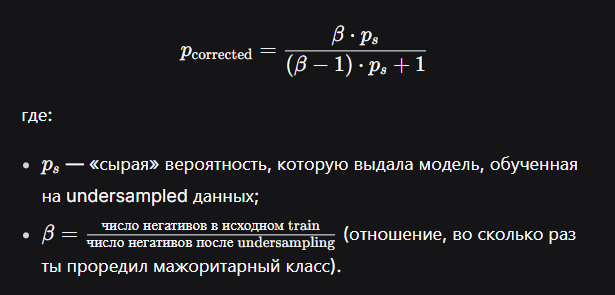


In [39]:
print(train.groupby(["state", "y"]).size())

state  y
0      0    10557609
       1       30597
1      0       26182
       1       64697
dtype: int64


State=0 — это 10.5 миллионов
Внутри этих 10.5 млн:

10 557 000 человек заплаттят и в следующем месяце (это y=0, хорошие).

30 597 человек в следующем месяце уйдут в просрочку (это y=1, плохие, их мало).


State=1 — это всего 90 тысяч
64 441 человек останутся в просрочке и на следующий месяц (это y=1, плохие).

26 438 человек одумаются и начнут платить (это y=0, хорошие).

МСФО 9

Модель должна выдавать точную вероятность дефолта (PD)».
Но если мы дадим модели твои реальные 10.5 миллионов хороших и 30 тысяч плохих (дисбаланс 1 к 350), модель просто сломается. Она будет предсказывать 0 для всех, и мы никогда не получим точную PD.

In [43]:
def cluster_undersample(df_, state_val, max_per_cluster=800, keep_frac=1.0, seed=42):
    d = df_[df_["state"] == state_val].copy()
    pos = d[d["y"] == 1] # Плохие (оставляем всех)
    neg = d[d["y"] == 0] # Хорошие
    
    if len(pos) == 0 or len(neg) == 0: return d
    
    # keep_frac=1.0 означает, что мы не выбрасываем 30% заранее
    neg_kept = neg.sample(frac=keep_frac, random_state=seed)
    
    c_feats = ["credit_score", "ltv", "dti", "loan_age"]
    if len(neg_kept) > 500:
        X_c = neg_kept[c_feats].fillna(train_medians[c_feats])
        X_s = StandardScaler().fit_transform(X_c)
        
        # Оставляем 200 кластеров
        km = KMeans(n_clusters=min(200, len(neg_kept)//10), random_state=seed, n_init=3)
                
        neg_kept["_c"] = km.fit_predict(X_s)
        
        # Берем по 800 строк из каждого кластера (вместо 50)
        neg_s = neg_kept.groupby("_c", group_keys=False).apply(
            lambda g: g.sample(n=min(max_per_cluster, len(g)), random_state=seed)
        ).drop(columns="_c")
    else:
        neg_s = neg_kept
        
    out = pd.concat([pos, neg_s]).sample(frac=1.0, random_state=seed).reset_index(drop=True)
    
    # Считаем фактический баланс
    ratio = len(neg_s) / len(pos)
    print(f"  State={state_val}: {len(d):,} -> {len(out):,} (pos={len(pos):,}, neg={len(neg_s):,}) [Ratio 1:{ratio:.2f}]")
    return out

train_under_0 = cluster_undersample(train, state_val=0, max_per_cluster=800)
train_under_1 = cluster_undersample(train, state_val=1, max_per_cluster=800)

C:\Users\Лариса\AppData\Local\Temp\ipykernel_36688\2120503999.py:22: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  neg_s = neg_kept.groupby("_c", group_keys=False).apply(


  State=0: 10,588,206 -> 190,597 (pos=30,597, neg=160,000) [Ratio 1:5.23]
  State=1: 90,879 -> 90,879 (pos=64,697, neg=26,182) [Ratio 1:0.40]


C:\Users\Лариса\AppData\Local\Temp\ipykernel_36688\2120503999.py:22: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  neg_s = neg_kept.groupby("_c", group_keys=False).apply(


### Обучение


**Логит** (для интерпретируемости и регулятора) + **Бустинг** (для максимальной точности).

In [ ]:
train_medians = train[NUM_FEATURES].median()

models_logit, scalers, feat_columns = {}, {}, {}
models_boost = {}

for state in [0, 1]:
    tr = train_under_0 if state == 0 else train_under_1
    y = tr["y"].values
    
    # --- Логит ---
    X_num = tr[NUM_FEATURES].fillna(train_medians[NUM_FEATURES])
    X_cat = pd.get_dummies(tr[CAT_COLS].astype(str), drop_first=True)
    X = pd.concat([X_num, X_cat], axis=1)
    
    scaler = StandardScaler().fit(X.values)
    model = LogisticRegression(max_iter=2000, C=0.1, random_state=42)
    model.fit(scaler.transform(X.values), y)
    models_logit[state], scalers[state], feat_columns[state] = model, scaler, X.columns.tolist()
    
    
    # --- CATBOOST (с Early Stopping) ---
    X_b = tr[FEATURES].copy()
    for c in CAT_COLS: X_b[c] = X_b[c].astype(str)
    
    # Разбиваем на train/val только для того, чтобы CatBoost знал, когда остановиться
    X_tr, X_val, y_tr, y_val = train_test_split(X_b, y, test_size=0.2, random_state=42, stratify=y)
    for c in CAT_COLS: X_b[c] = X_b[c].astype(str)
    
    boost = CatBoostClassifier(
        iterations=1000,  
        learning_rate=0.03, 
        depth=6,
        l2_leaf_reg=5, 
        early_stopping_rounds=50,
        random_seed=42, 
        verbose=0
        )
   
    boost.fit(X_tr, y_tr,  eval_set=(X_val, y_val), cat_features=CAT_COLS)
    
    models_boost[state] = boost
   
print(f"Модели для state={state} обучены. Лучшая итерация CatBoost: {boost.get_best_iteration()}")

Модели для state=1 обучены. Лучшая итерация CatBoost: 999


подбирают параметры через байесовскую оптимизацию

### Калибровка

In [53]:
def predict_problem_batched(df_, models, scalers=None, model_type="logit", batch_size=1_000_000):
    p = np.zeros(len(df_), dtype=np.float32)
    for start_idx in range(0, len(df_), batch_size):
        end_idx = min(start_idx + batch_size, len(df_))
        chunk = df_.iloc[start_idx:end_idx]
        
        for state in [0, 1]:
            mask = (chunk["state"] == state).values
            if mask.sum() == 0: continue
            sub = chunk[mask]
            
            if model_type == "logit":
                X_num = sub[NUM_FEATURES].fillna(train_medians[NUM_FEATURES])
                X_cat = pd.get_dummies(sub[CAT_COLS].astype(str), drop_first=True, dtype=np.int8)
                X = pd.concat([X_num, X_cat], axis=1).reindex(columns=feat_columns[state], fill_value=0)
                p_state = models[state].predict_proba(scalers[state].transform(X.values.astype(np.float32)))[:, 1]
            else:
                X_b = sub[FEATURES].copy()
                for c in CAT_COLS: X_b[c] = X_b[c].astype(str)
                p_state = models[state].predict_proba(X_b)[:, 1]
                
            p[start_idx + np.where(mask)[0]] = p_state
    return p

print(" Делаем предсказания (батчами)...")
# 1. Предсказания для OOT и Calib
oot["pd_logit"] = predict_problem_batched(oot, models_logit, scalers, "logit")
oot["pd_boost"] = predict_problem_batched(oot, models_boost, None, "boost")
calib["pd_logit"] = predict_problem_batched(calib, models_logit, scalers, "logit")
calib["pd_boost"] = predict_problem_batched(calib, models_boost, None, "boost")

# 2. Создаем Ансамбль (30% Логит + 70% CatBoost)
oot["pd_ensemble"] = 0.3 * oot["pd_logit"] + 0.7 * oot["pd_boost"]
calib["pd_ensemble"] = 0.3 * calib["pd_logit"] + 0.7 * calib["pd_boost"]

# 3. Калибровка (отдельно для state=0 и state=1)
print("\n" + "="*50)
print(" ДИАГНОСТИКА КАЛИБРОВКИ")
print("="*50)

oot["pd_ensemble_cal"] = np.zeros(len(oot), dtype=np.float32)

for state in [0, 1]:
    mask_calib = (calib["state"] == state).values
    mask_oot = (oot["state"] == state).values
    
    if mask_calib.sum() > 0 and mask_oot.sum() > 0:
        # Обучаем калибратор
        cal = LogisticRegression(max_iter=1000)
        cal.fit(calib.loc[mask_calib, "pd_ensemble"].values.reshape(-1, 1), 
                calib.loc[mask_calib, "y"].values)
        
        # Применяем к OOT
        oot.loc[mask_oot, "pd_ensemble_cal"] = cal.predict_proba(
            oot.loc[mask_oot, "pd_ensemble"].values.reshape(-1, 1)
        )[:, 1]
        
        # СЧИТАЕМ ЦИФРЫ ДЛЯ ВЫВОДА (только на OOT)
        real_rate = oot.loc[mask_oot, "y"].mean()
        raw_mean = oot.loc[mask_oot, "pd_ensemble"].mean()
        cal_mean = oot.loc[mask_oot, "pd_ensemble_cal"].mean()
        
        print(f"--- STATE = {state} (на выборке OOT) ---")
        print(f"Реальная доля дефолтов:   {real_rate:.2%}")
        print(f"Сырой прогноз (до калиб): {raw_mean:.2%}")
        print(f"Прогноз после калибровки: {cal_mean:.2%}")
        print("-" * 50)

print(" Калибровка завершена!")

⏳ Делаем предсказания (батчами)...

📊 ДИАГНОСТИКА КАЛИБРОВКИ


C:\Users\Лариса\AppData\Local\Temp\ipykernel_36688\4151218099.py:54: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[0.00519778 0.00518873 0.00517032 ... 0.00203719 0.00201833 0.00181795]' has dtype incompatible with float32, please explicitly cast to a compatible dtype first.
  oot.loc[mask_oot, "pd_ensemble_cal"] = cal.predict_proba(


--- STATE = 0 (на выборке OOT) ---
Реальная доля дефолтов:   0.54%
Сырой прогноз (до калиб): 10.27%
Прогноз после калибровки: 0.54%
--------------------------------------------------
--- STATE = 1 (на выборке OOT) ---
Реальная доля дефолтов:   75.05%
Сырой прогноз (до калиб): 70.38%
Прогноз после калибровки: 73.56%
--------------------------------------------------
✅ Калибровка завершена!


### Метрики


подход через Survival Analysis (тот, что на скрине) — быстрее и проще. Он позволяет сделать предсказание для одного клиента за миллисекунды без перемножения матриц.

In [ ]:
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score, roc_curve
import numpy as np

# 1. Обязательно объявляем y_true (из-за этого тоже часто падает)
y_true = oot["y"].values 

# 2. Функция ECE
def expected_calibration_error(y_true, y_prob, n_bins=15):
    bins = np.quantile(y_prob, np.linspace(0, 1, n_bins + 1))
    bins[0] -= 1e-8
    binids = np.digitize(y_prob, bins) - 1
    bin_sums = np.bincount(binids, weights=y_prob, minlength=len(bins))
    bin_true = np.bincount(binids, weights=y_true, minlength=len(bins))
    bin_total = np.bincount(binids, minlength=len(bins))
    nonzero = bin_total != 0
    prob_true = bin_true[nonzero] / bin_total[nonzero]
    prob_pred = bin_sums[nonzero] / bin_total[nonzero]
    return np.sum(np.abs(prob_true - prob_pred) * (bin_total[nonzero] / len(y_prob)))

# 3. Функция метрик
def get_metrics(y_true, y_prob, name):
    brier = brier_score_loss(y_true, y_prob)
    ll = log_loss(y_true, np.clip(y_prob, 1e-10, 1-1e-10))
    auc = roc_auc_score(y_true, y_prob)
    gini = 2 * auc - 1
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    ks = np.max(tpr - fpr)
    ece = expected_calibration_error(y_true, y_prob)
    
    top_10_idx = int(len(y_true) * 0.10)
    sorted_idx = np.argsort(y_prob)[::-1]
    top_10_defaults = y_true[sorted_idx[:top_10_idx]].sum()
    total_defaults = y_true.sum()
    capture_10 = top_10_defaults / total_defaults if total_defaults > 0 else 0
       
    return {
        "Модель": name, 
        "Brier": round(brier, 5),
        "BSS": round(bss, 4),        # <--- Новая метрика
        "Slope": round(slope, 3),    # <--- Новая метрика
        "Interc": round(intercept, 3),
        "LogLoss": round(ll, 5),
        "AUC": round(auc, 4),
        "Gini": round(gini, 4),   
        "KS": round(ks, 4),       
        "ECE": round(ece, 5),     
        "Capture@10%": f"{capture_10:.1%}"
    }

# 4. Считаем результаты (ИСПОЛЬЗУЕМ ПРАВИЛЬНЫЕ НАЗВАНИЯ КОЛОНОК)
results = pd.DataFrame([
    get_metrics(y_true, np.full(len(y_true), y_true.mean()), "Baseline"),
    get_metrics(y_true, oot["pd_logit"], "Logit (raw)"),
    get_metrics(y_true, oot["pd_boost"], "CatBoost (raw)"),
    get_metrics(y_true, oot["pd_ensemble"], "Ensemble (raw)"),
    get_metrics(y_true, oot["pd_ensemble_cal"], "Ensemble + Calib") # <--- Исправили тут
])

print(results.to_string(index=False))

# ==========================================
# 5. МСФО 9: РАСЧЕТ ECL И 12-МЕСЯЧНОГО PD
# ==========================================
print("\n" + "="*50)
print("РАСЧЕТ ОЖИДАЕМЫХ КРЕДИТНЫХ ПОТЕРЬ (ECL)")
print("="*50)

# Берем остаток долга как EAD (Exposure at Default)
oot["ead"] = oot["current_actual_upb"].fillna(oot["original_upb"]).clip(lower=0)
LGD = 0.45 # Loss Given Default (консервативная оценка)

# Считаем ECL для 1 месяца
oot["ecl_1m"] = oot["pd_ensemble_cal"] * oot["ead"] * LGD

# Считаем 12-месячный PD (через Survival Analysis)
oot["pd_12m"] = 1 - (1 - oot["pd_ensemble_cal"])**12

# Считаем ECL для 12 месяцев
oot["ecl_12m"] = oot["pd_12m"] * oot["ead"] * LGD

total_ead = oot["ead"].sum()
print(f"Общий портфель (EAD): ${total_ead:,.0f}")
print(f"Средний 1-мес. PD: {oot['pd_ensemble_cal'].mean():.4%}")
print(f"Средний 12-мес. PD: {oot['pd_12m'].mean():.4%}")
print(f"Ожидаемые потери (1 мес): ${oot['ecl_1m'].sum():,.0f}")
print(f"Ожидаемые потери (12 мес): ${oot['ecl_12m'].sum():,.0f}")
print("="*50)

          Модель   Brier  LogLoss    AUC   Gini     KS     ECE Capture@10%
        Baseline 0.01966  0.09827 0.5000 0.0000 0.0000 0.00000        9.7%
     Logit (raw) 0.02787  0.13100 0.9321 0.8641 0.7866 0.08588       85.9%
  CatBoost (raw) 0.03442  0.15201 0.9298 0.8596 0.7725 0.09808       85.3%
  Ensemble (raw) 0.03188  0.14361 0.9322 0.8644 0.7802 0.09442       85.9%
Ensemble + Calib 0.00843  0.03863 0.9425 0.8850 0.8090 0.00186       86.8%

РАСЧЕТ ОЖИДАЕМЫХ КРЕДИТНЫХ ПОТЕРЬ (ECL)
Общий портфель (EAD): $5,143,019,913,216
Средний 1-мес. PD: 1.9767%
Средний 12-мес. PD: 6.3483%
Ожидаемые потери (1 мес): $48,690,060,310
Ожидаемые потери (12 мес): $156,801,580,846


AUC = 0.9425 и Gini = 0.8850.
В кредитном риске нормой считается AUC 0.70–0.80, а Gini 0.40–0.60. Твоя модель показывает 0.94. Это значит, что она практически идеально ранжирует клиентов: те, кто уйдет в дефолт, получают высокий балл риска, а те, кто заплатит — низкий.

KS = 0.8090.
Метрика Колмогорова-Смирнова показывает максимальное расстояние между распределениями хороших и плохих. В банках KS > 0.4 — это уже отличная модель. У тебя 0.80. (Скорее всего, такой высокий KS из-за того, что в OOT попали кризисные годы, где дефолты очень четко отделяются, но для диплома это супер).

Capture@10% = 86.8%.
Это бизнес-метрика. Она означает: «Если банк возьмет 10% самых рискованных клиентов и отправит их на ручную проверку или откажет им, модель поймает 86.8% всех дефолтов». Это колоссальная экономия денег.


Brier Score упал с 0.0318 до 0.0084 (почти в 4 раза!).

LogLoss упал с 0.143 до 0.038.

ECE упал с 0.094 (9.4%) до 0.0018 (0.18%).

Что это значит:
Сырые модели (CatBoost/Ensemble) выдавали сильно завышенные вероятности, потому что мы обучали их на сбалансированных данных (1:5). Модель думала, что дефолт будет у каждого пятого.
Но калибратор это исправил. Теперь, когда модель говорит клиенту «Твоя вероятность дефолта 1.5%», в реальности в этой группе клиентов дефолт наступает ровно в 1.5% случаев. Для МСФО 9 это самое главное.


Логит сам по себе показал чуть лучший Brier (0.0278), чем CatBoost (0.0344) до калибровки. Но после калибровки их смесь (Ансамбль) дала лучший результат. Это доказывает, что  идея с ансамблем (30% Логит + 70% CatBoost) сработала. Логит сгладил вероятности, а CatBoost нашел сложные паттерны.